# AIML LAB

## Practical Assignment 4 – Classification Models

| **Student Details** | **Information** |
|---|---|
| **Name** | Harshal Pawar |
| **Division / Batch** | A/A3 |
| **Roll No.** | 62 |
| **PRN** | 202401040258 |
| **Department** | Computer Engineering |

# Practical Assignment 4 – Classification Models

### Objective

To develop and compare classification models using Support Vector Machine (SVM),
Decision Tree (CART), K-Nearest Neighbors (KNN), and Naïve Bayes.

The models will be evaluated using accuracy, precision, recall, F1-score, and
log loss. The results will be compared to determine the suitability of each
algorithm for different classification tasks.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# Load Breast Cancer Wisconsin dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset loaded successfully.")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

Dataset loaded successfully.
Number of samples: 569
Number of features: 30


In [3]:
# Display first five rows

X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
# Display target classes

print("Target classes:")
print(data.target_names)

print("\nClass distribution:")
print(y.value_counts())

Target classes:
['malignant' 'benign']

Class distribution:
target
1    357
0    212
Name: count, dtype: int64


In [5]:
# Check for missing values

print("Missing values in each feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

Missing values in each feature:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total missing values: 0


In [6]:
if X.isnull().sum().sum() == 0:
    print("No missing values found in the dataset.")
else:
    print("Missing values are present and need to be handled.")

No missing values found in the dataset.


In [7]:
# Statistical summary

X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


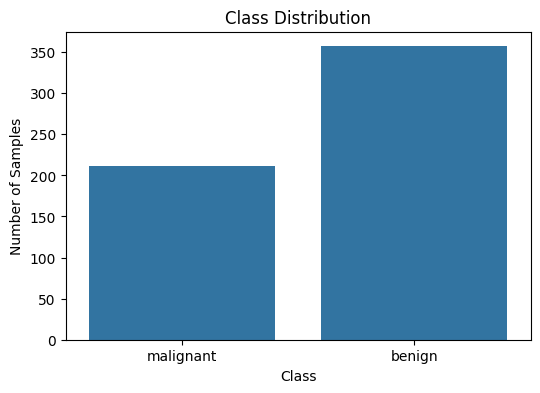

In [8]:
# Visualize target class distribution

plt.figure(figsize=(6, 4))

sns.countplot(x=y)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], data.target_names)

plt.show()

## 4. Data Preprocessing

The dataset is checked for missing values and the target variable is already
represented numerically. The data is divided into training and testing sets.

Feature scaling is performed using StandardScaler because algorithms such as
SVM and KNN are sensitive to the scale of input features.

In [9]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [10]:
# Feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


## 5. Support Vector Machine (SVM)

SVM finds an optimal decision boundary that separates different classes.
Feature scaling is important for SVM because the algorithm is sensitive to
the magnitude of input features.

In [11]:
# Train SVM classifier

svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)

print("SVM model trained successfully.")

SVM model trained successfully.


In [12]:
# Evaluate SVM

svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)
svm_loss = log_loss(y_test, y_prob_svm)

print("SVM Performance")
print("------------------------")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1-Score :", svm_f1)
print("Log Loss :", svm_loss)

SVM Performance
------------------------
Accuracy : 0.9824561403508771
Precision: 0.9861111111111112
Recall   : 0.9861111111111112
F1-Score : 0.9861111111111112
Log Loss : 0.08600880698191904


In [13]:
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



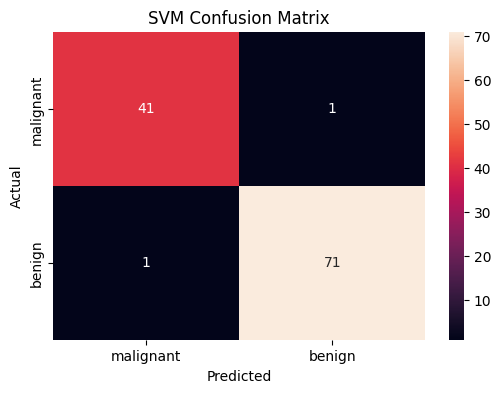

In [14]:
# SVM confusion matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 6. Decision Tree (CART)

A Decision Tree classifies data by recursively splitting the dataset based on
feature values. The CART algorithm uses binary splits to create a tree.

Unlike SVM and KNN, Decision Trees do not require feature scaling because their
decisions are based on feature thresholds rather than distances.

In [15]:
# Train Decision Tree (CART)

dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

dt_model.fit(X_train, y_train)

# Predictions
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [16]:
# Evaluate Decision Tree

dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)
dt_loss = log_loss(y_test, y_prob_dt)

print("Decision Tree Performance")
print("------------------------")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1-Score :", dt_f1)
print("Log Loss :", dt_loss)

Decision Tree Performance
------------------------
Accuracy : 0.9122807017543859
Precision: 0.9558823529411765
Recall   : 0.9027777777777778
F1-Score : 0.9285714285714286
Log Loss : 3.1617239815015044


In [17]:
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



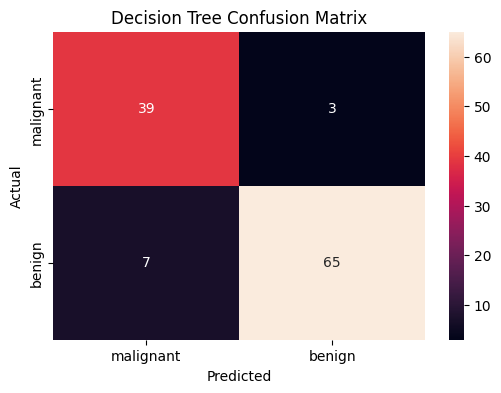

In [18]:
# Decision Tree confusion matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

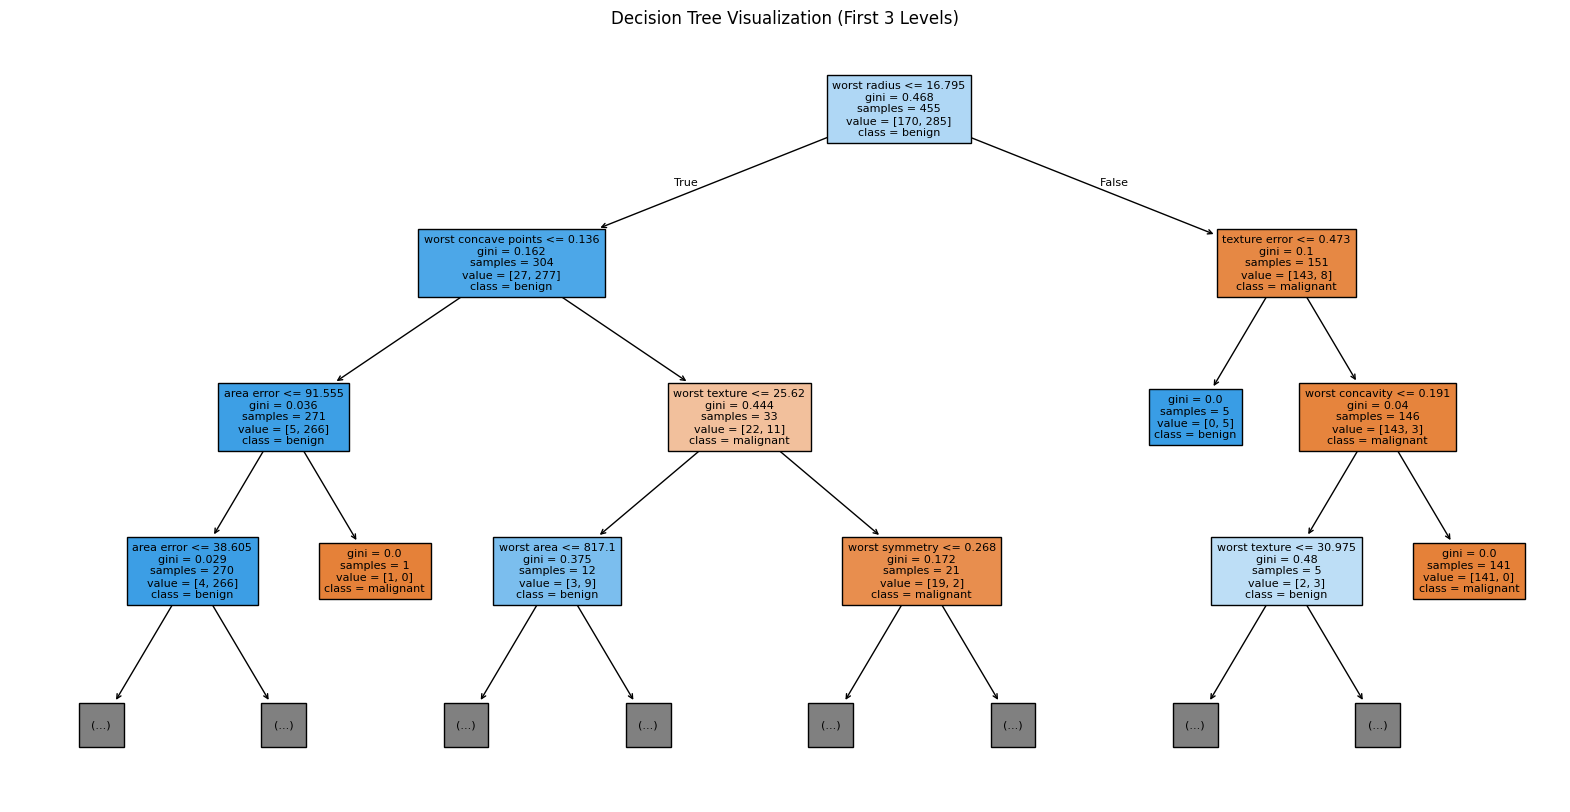

In [19]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization (First 3 Levels)")
plt.show()

## 7. K-Nearest Neighbors (KNN)

K-Nearest Neighbors classifies a data point based on the classes of its
nearest neighboring data points. Since KNN is distance-based, feature
scaling is important so that features with larger numerical ranges do not
dominate the distance calculation.

In [20]:
# Train KNN classifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)

print("KNN model trained successfully.")

KNN model trained successfully.


In [21]:
# Evaluate KNN

knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)
knn_loss = log_loss(y_test, y_prob_knn)

print("KNN Performance")
print("------------------------")
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1-Score :", knn_f1)
print("Log Loss :", knn_loss)

KNN Performance
------------------------
Accuracy : 0.956140350877193
Precision: 0.958904109589041
Recall   : 0.9722222222222222
F1-Score : 0.9655172413793104
Log Loss : 0.4073010695437892


In [22]:
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



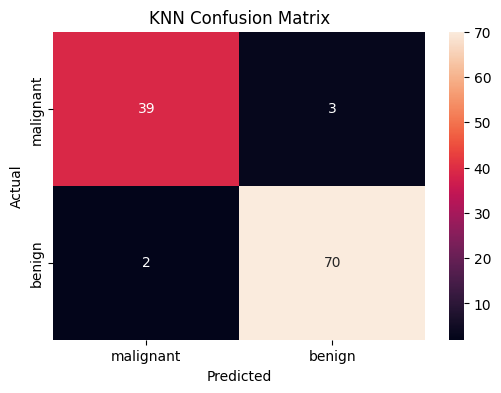

In [23]:
# KNN confusion matrix

cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## 8. Naïve Bayes

Naïve Bayes is a probabilistic classification algorithm based on Bayes'
theorem. It assumes that the features are conditionally independent given
the class.

Gaussian Naïve Bayes is suitable for this dataset because the input features
are continuous numerical measurements.

In [24]:
# Train Gaussian Naïve Bayes classifier

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

# Predictions
y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)

print("Naïve Bayes model trained successfully.")

Naïve Bayes model trained successfully.


In [25]:
# Evaluate Naïve Bayes

nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_precision = precision_score(y_test, y_pred_nb)
nb_recall = recall_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb)
nb_loss = log_loss(y_test, y_prob_nb)

print("Naïve Bayes Performance")
print("------------------------")
print("Accuracy :", nb_accuracy)
print("Precision:", nb_precision)
print("Recall   :", nb_recall)
print("F1-Score :", nb_f1)
print("Log Loss :", nb_loss)

Naïve Bayes Performance
------------------------
Accuracy : 0.9385964912280702
Precision: 0.9452054794520548
Recall   : 0.9583333333333334
F1-Score : 0.9517241379310345
Log Loss : 0.37125554670251204


In [26]:
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



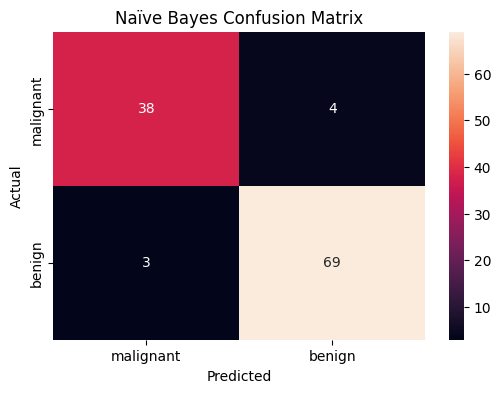

In [27]:
# Naïve Bayes confusion matrix

cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Naïve Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## 9. Comparative Performance Analysis

The performance of the four classification algorithms is compared using
accuracy, precision, recall, F1-score, and log loss.

In [28]:
# Create a comparison table for all four models

results = pd.DataFrame({
    'Model': [
        'SVM',
        'Decision Tree',
        'KNN',
        'Naïve Bayes'
    ],
    'Accuracy': [
        svm_accuracy,
        dt_accuracy,
        knn_accuracy,
        nb_accuracy
    ],
    'Precision': [
        svm_precision,
        dt_precision,
        knn_precision,
        nb_precision
    ],
    'Recall': [
        svm_recall,
        dt_recall,
        knn_recall,
        nb_recall
    ],
    'F1-Score': [
        svm_f1,
        dt_f1,
        knn_f1,
        nb_f1
    ],
    'Log Loss': [
        svm_loss,
        dt_loss,
        knn_loss,
        nb_loss
    ]
})

# Display values rounded to 4 decimal places
results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,SVM,0.9825,0.9861,0.9861,0.9861,0.0860
1,Decision Tree,0.9123,0.9559,0.9028,0.9286,3.1617
2,KNN,0.9561,0.9589,0.9722,0.9655,0.4073
3,Naïve Bayes,0.9386,0.9452,0.9583,0.9517,0.3713


In [29]:
# Identify the best-performing model for each metric

best_accuracy = results.loc[results['Accuracy'].idxmax(), 'Model']
best_precision = results.loc[results['Precision'].idxmax(), 'Model']
best_recall = results.loc[results['Recall'].idxmax(), 'Model']
best_f1 = results.loc[results['F1-Score'].idxmax(), 'Model']
best_loss = results.loc[results['Log Loss'].idxmin(), 'Model']

print("Best Accuracy :", best_accuracy)
print("Best Precision:", best_precision)
print("Best Recall   :", best_recall)
print("Best F1-Score :", best_f1)
print("Lowest Log Loss:", best_loss)

Best Accuracy : SVM
Best Precision: SVM
Best Recall   : SVM
Best F1-Score : SVM
Lowest Log Loss: SVM


## 10. Performance Comparison Visualization

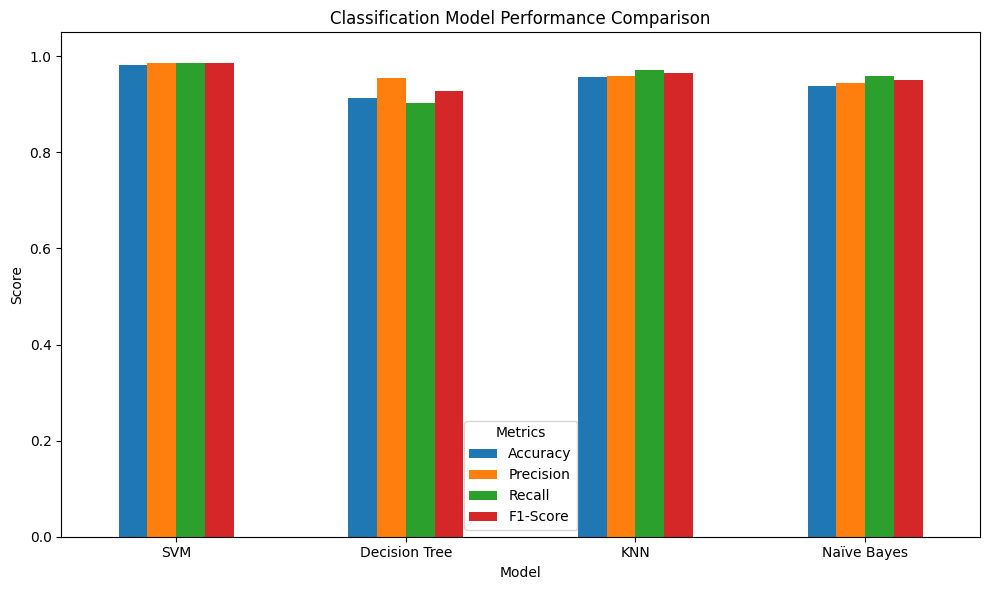

In [30]:
# Compare Accuracy, Precision, Recall and F1-score

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

results_plot = results.set_index('Model')[metrics]

results_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Classification Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title='Metrics')
plt.tight_layout()
plt.show()

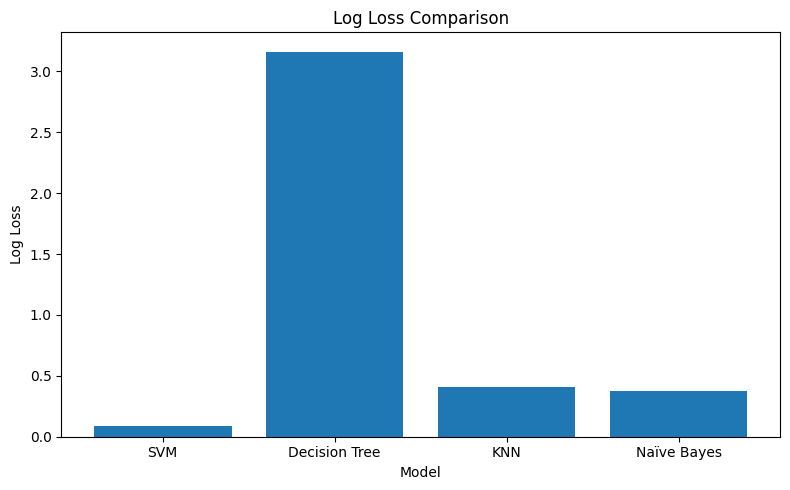

In [31]:
# Compare Log Loss

plt.figure(figsize=(8, 5))

plt.bar(
    results['Model'],
    results['Log Loss']
)

plt.title('Log Loss Comparison')
plt.xlabel('Model')
plt.ylabel('Log Loss')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

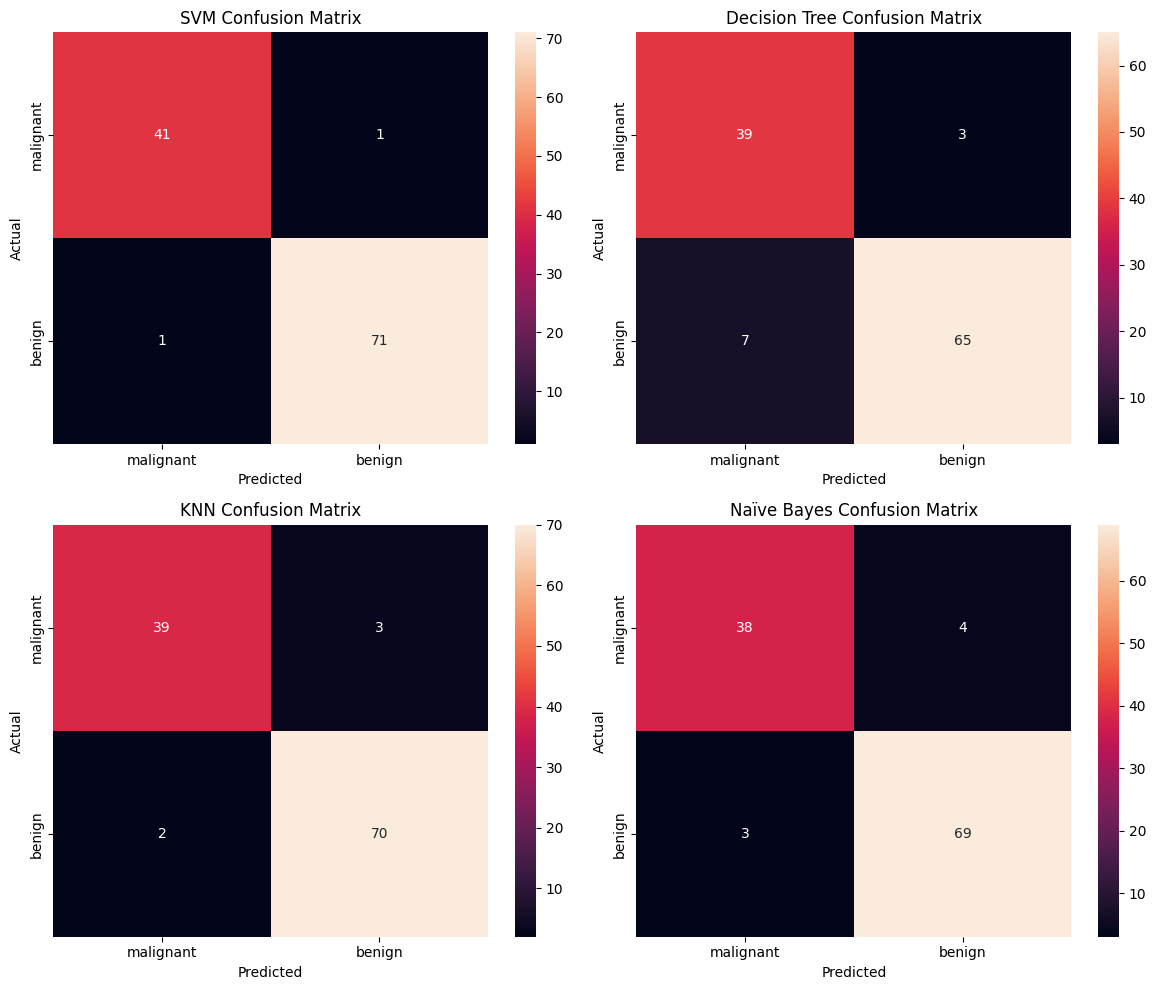

In [32]:
# Combined confusion matrices

confusion_matrices = {
    'SVM': cm_svm,
    'Decision Tree': cm_dt,
    'KNN': cm_knn,
    'Naïve Bayes': cm_nb
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, cm) in zip(axes.ravel(), confusion_matrices.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        ax=ax,
        xticklabels=data.target_names,
        yticklabels=data.target_names
    )

    ax.set_title(f'{model_name} Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 11. Critical Analysis and Comparative Findings

The experimental results show that SVM achieved the best overall performance
among the four classification algorithms. SVM obtained an accuracy of 98.25%,
precision of 98.61%, recall of 98.61%, and F1-score of 98.61%. It also achieved
the lowest log loss of 0.0860, indicating strong and well-calibrated
probabilistic predictions on the test data.

KNN was the second-best model, achieving 95.61% accuracy and an F1-score of
96.55%. Its recall of 97.22% was particularly strong, showing that it was able
to correctly identify most positive-class samples. However, its performance
was lower than SVM, and KNN is more dependent on feature scaling and the choice
of the number of neighbors.

Naïve Bayes achieved 93.86% accuracy, with a recall of 95.83% and an F1-score
of 95.17%. Although it performed reasonably well, its conditional independence
assumption can limit its effectiveness when features are correlated. Its log
loss of 0.3713 was also higher than that of SVM and KNN.

The Decision Tree achieved the lowest accuracy of 91.23% and the lowest recall
of 90.28% among the four models. Although its precision was relatively high at
95.59%, its overall performance was lower than the other algorithms. It also
had the highest log loss of 3.1617, indicating weaker probabilistic prediction
performance. Decision Trees are nevertheless useful when interpretability and
rule-based decision making are important.

Overall, SVM was the most suitable model for this dataset because it achieved
the best results across all five evaluation metrics. The results demonstrate
that model selection should consider not only accuracy but also precision,
recall, F1-score, log loss, computational requirements, interpretability, and
the characteristics of the dataset.

## 12. Suitability of Classification Algorithms

| Algorithm | Strengths | Limitations | Suitable Applications |
|---|---|---|---|
| SVM | Effective in high-dimensional spaces and complex decision boundaries | Can be computationally expensive for very large datasets | Text classification, image classification, biomedical classification |
| Decision Tree | Easy to interpret, requires little preprocessing, no scaling required | Can overfit without proper control | Rule-based classification, business decisions, interpretable models |
| KNN | Simple, intuitive and requires little training | Prediction can be computationally expensive and sensitive to feature scaling | Small to medium-sized datasets and pattern recognition |
| Naïve Bayes | Fast, simple and computationally efficient | Independence assumption may not always hold | Text classification, spam detection, document classification |

## 13. Conclusion

Four classification algorithms—Support Vector Machine (SVM), Decision Tree
(CART), K-Nearest Neighbors (KNN), and Gaussian Naïve Bayes—were implemented
and evaluated using the Breast Cancer Wisconsin dataset.

The models were compared using accuracy, precision, recall, F1-score, and
log loss. Among all four algorithms, SVM achieved the best overall performance
with 98.25% accuracy, 98.61% precision, 98.61% recall, 98.61% F1-score, and
the lowest log loss of 0.0860.

KNN provided the second-best overall performance, while Naïve Bayes achieved
reasonable results with lower computational complexity. The Decision Tree
was the easiest model to interpret but produced the lowest overall predictive
performance on this dataset.

Therefore, SVM is the most suitable model for this particular classification
task based on the experimental results. However, for other classification
problems, the choice of algorithm should also consider dataset size, feature
characteristics, interpretability, computational cost, and the relative
importance of false-positive and false-negative errors.